# The State of Secondary Education in Padington — Exploratory Data Analysis & Hypothesis Testing

**Dataset:** `padington_education_dataset.csv` — 50,000 student records, 16 variables
**Prepared by:** Bashir Omondi Nuru
**Tools:** Python · pandas · NumPy · SciPy · statsmodels · matplotlib · seaborn

---

## Contents
1. Introduction and research questions
2. Setup and data loading (including a data-loading pitfall)
3. Data quality audit
4. Feature engineering
5. Exploratory data analysis (univariate → bivariate → multivariate)
6. Hypothesis development
7. Hypothesis testing (H1–H8)
8. Multivariate model (OLS regression)
9. Data-credibility assessment
10. Summary of findings
11. Statement on the state of education in Padington
12. Limitations and recommendations

---

## 1. Introduction

*Padington* is a hypothetical country used as a pseudonym throughout this analysis. Its upper-secondary students follow one of three tracks:

| Track | Description |
|---|---|
| **National** | Padington's national secondary certificate. It is public and exam-driven, and its final score largely decides university placement. |
| **IGCSE** | The British (Cambridge/Edexcel) curriculum, offered mainly in private and international schools. |
| **IB** | The International Baccalaureate, offered by a small number of fee-paying international schools. |

Debates about education systems like Padington's often turn on three questions: whether the **international tracks produce better results** than the national track, how much **family background** (parental education) decides outcomes, and whether students **progress** as they move through the years.

### Research questions
- **RQ1.** Does academic performance differ across the education types (National, IGCSE, IB)?
- **RQ2.** Is parental education (father's and mother's) associated with student performance?
- **RQ3.** Does performance change across school years, and do over-age students perform differently?
- **RQ4.** Is access to each education type related to family educational background?
- **RQ5.** Is performance consistent across subjects, i.e. is there a general "academic ability" signal?

## 2. Setup and data loading

In [1]:
import warnings, zipfile, os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.power import FTestAnovaPower, TTestIndPower

# ---- consistent, colour-blind-checked palette ----
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
sns.set_theme(style="white", palette=PALETTE)
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.titleweight": "bold",
    "axes.titlesize": 12, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
pd.set_option("display.float_format", "{:.3f}".format)
ALPHA = 0.05
print("Libraries loaded.")

Libraries loaded.


### 2.1 A data-loading pitfall: `"None"` is not missing data

By default `pd.read_csv` converts the literal string `"None"` to `NaN`. In this dataset, `"None"` in *Father Degree* / *Mother Degree* is a **real category**: the parent holds no formal qualification. Loading naïvely would wrongly report about 20% of parental education as "missing" and would quietly drop the most disadvantaged group from any analysis. The two loads are compared below.

In [2]:
CSV = "padington_education_dataset.csv"
ZIP = "padington_education_dataset.csv.zip"
def _open():
    if os.path.exists(CSV):
        return CSV
    return zipfile.ZipFile(ZIP).open(CSV)

naive = pd.read_csv(_open())
df    = pd.read_csv(_open(), keep_default_na=False, na_values=[""])

print("Naive load  - 'missing' parental degrees:",
      naive[["Father Degree", "Mother Degree"]].isna().sum().to_dict())
print("Correct load - 'missing' parental degrees:",
      df[["Father Degree", "Mother Degree"]].isna().sum().to_dict())
print("\nShape:", df.shape)
df.head()

Naive load  - 'missing' parental degrees: {'Father Degree': 10040, 'Mother Degree': 10090}
Correct load - 'missing' parental degrees: {'Father Degree': 0, 'Mother Degree': 0}

Shape: (50000, 16)


,Student Name,Student Age,Student year,Father Degree,Mother Degree,Education Type,Subject_1,Subject_2,Subject_3,Subject_4,Subject_5,Subject_6,Subject_7,Subject_8,Subject_9,Subject_10
0,Allison Lang,18,Year 9,High School,High School,IB,72.237,85.931,65.699,84.164,78.179,50.578,70.072,80.295,72.710,59.081
1,Jaclyn Mcneil,14,Year 9,Bachelor,PhD,IB,91.603,73.186,64.240,47.787,83.139,66.914,42.587,87.997,89.177,78.493
2,Melissa Lee,16,Year 10,None,PhD,IB,100.000,83.986,89.378,82.447,86.369,90.347,100.000,83.972,69.213,79.207
3,Timothy Maxwell,14,Year 10,Bachelor,Bachelor,National,91.082,100.000,78.802,78.448,64.606,82.045,69.869,91.123,95.208,52.603
4,Eric Steele,17,Year 11,PhD,None,IGCSE,74.906,69.518,65.285,56.317,69.758,85.811,63.777,61.803,84.951,68.146


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Student Name    50000 non-null  str    
 1   Student Age     50000 non-null  int64  
 2   Student year    50000 non-null  str    
 3   Father Degree   50000 non-null  str    
 4   Mother Degree   50000 non-null  str    
 5   Education Type  50000 non-null  str    
 6   Subject_1       50000 non-null  float64
 7   Subject_2       50000 non-null  float64
 8   Subject_3       50000 non-null  float64
 9   Subject_4       50000 non-null  float64
 10  Subject_5       50000 non-null  float64
 11  Subject_6       50000 non-null  float64
 12  Subject_7       50000 non-null  float64
 13  Subject_8       50000 non-null  float64
 14  Subject_9       50000 non-null  float64
 15  Subject_10      50000 non-null  float64
dtypes: float64(10), int64(1), str(5)
memory usage: 6.1 MB


## 3. Data quality audit

In [4]:
SUBJECTS = [f"Subject_{i}" for i in range(1, 11)]
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique": df.nunique(),
})
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated student names:", df["Student Name"].duplicated().sum(),
      "(common names repeated, not duplicate records - see full-row check above)")
print("Score range: min = {:.1f}, max = {:.1f}".format(df[SUBJECTS].min().min(), df[SUBJECTS].max().max()))
audit

Fully duplicated rows: 0
Duplicated student names: 9889 (common names repeated, not duplicate records - see full-row check above)
Score range: min = 20.0, max = 100.0


,dtype,missing,unique
Student Name,str,0,40111
Student Age,int64,0,5
Student year,str,0,4
Father Degree,str,0,5
Mother Degree,str,0,5
Education Type,str,0,3
Subject_1,float64,0,47652
Subject_2,float64,0,47591
Subject_3,float64,0,47638
Subject_4,float64,0,47586


In [5]:
for c in ["Student Age", "Student year", "Father Degree", "Mother Degree", "Education Type"]:
    vc = df[c].value_counts().sort_index()
    print(f"{c}:\n" + (vc.astype(str) + "  (" + (vc / len(df) * 100).round(1).astype(str) + "%)").to_string(), "\n")

Student Age:
Student Age
14     9956  (19.9%)
15    10051  (20.1%)
16     9948  (19.9%)
17     9943  (19.9%)
18    10102  (20.2%) 

Student year:
Student year
Year 10    12669  (25.3%)
Year 11    12346  (24.7%)
Year 12    12438  (24.9%)
Year 9     12547  (25.1%) 

Father Degree:
Father Degree
Bachelor       10197  (20.4%)
High School     9946  (19.9%)
Master          9718  (19.4%)
None           10040  (20.1%)
PhD            10099  (20.2%) 

Mother Degree:
Mother Degree
Bachelor       10014  (20.0%)
High School    10007  (20.0%)
Master          9978  (20.0%)
None           10090  (20.2%)
PhD             9911  (19.8%) 

Education Type:
Education Type
IB          16977  (34.0%)
IGCSE       16478  (33.0%)
National    16545  (33.1%) 



In [6]:
# Boundary checks: how many scores sit exactly on the floor (20) or ceiling (100)?
bounds = pd.DataFrame({
    "% at 100 (ceiling)": (df[SUBJECTS] == 100).mean() * 100,
    "% at 20 (floor)":    (df[SUBJECTS] == 20).mean() * 100,
}).round(2)
bounds.T

,Subject_1,Subject_2,Subject_3,Subject_4,Subject_5,Subject_6,Subject_7,Subject_8,Subject_9,Subject_10
% at 100 (ceiling),4.690,4.810,4.720,4.810,4.770,4.840,4.710,4.830,4.650,4.810
% at 20 (floor),0.010,0.010,0.000,0.020,0.010,0.010,0.020,0.020,0.010,0.000


**Audit findings**
- There are **no missing values** once `"None"` is read correctly, and **no duplicate records**.
- Scores lie between **20 and 100**. About **4.7% of every subject's scores sit exactly at 100**, a *ceiling effect* that shows the scores were capped. This matters for normality assumptions later.
- Categories are **almost perfectly balanced**. Each education type holds about 33%, each parental degree level about 20%, each age (14–18) about 20% and each year about 25%. Real enrolment data are rarely this even. We return to this point in Section 9.

## 4. Feature engineering

In [7]:
DEG_ORDER = ["None", "High School", "Bachelor", "Master", "PhD"]
DEG_RANK  = {d: i for i, d in enumerate(DEG_ORDER)}
YEAR_ORDER = ["Year 9", "Year 10", "Year 11", "Year 12"]
EDU_ORDER  = ["National", "IGCSE", "IB"]

df["Average"] = df[SUBJECTS].mean(axis=1)
df["SD_across_subjects"] = df[SUBJECTS].std(axis=1)
df["Subjects_failed"] = (df[SUBJECTS] < 50).sum(axis=1)
df["Pass_all"] = df["Subjects_failed"].eq(0)

df["Father_rank"] = df["Father Degree"].map(DEG_RANK)
df["Mother_rank"] = df["Mother Degree"].map(DEG_RANK)
df["Parent_max_rank"] = df[["Father_rank", "Mother_rank"]].max(axis=1)
df["Parent_max_degree"] = pd.Categorical(df["Parent_max_rank"].map(dict(enumerate(DEG_ORDER))), DEG_ORDER, ordered=True)
df["First_generation"] = df["Parent_max_rank"] <= 1          # neither parent has a university degree

for c, order in [("Father Degree", DEG_ORDER), ("Mother Degree", DEG_ORDER),
                 ("Student year", YEAR_ORDER), ("Education Type", EDU_ORDER)]:
    df[c] = pd.Categorical(df[c], order, ordered=True)

df["Year_num"] = df["Student year"].cat.codes + 9
# In a typical system a Year-9 student is about 14, Year 10 about 15, and so on.
df["Expected_age"] = df["Year_num"] + 5
df["Age_gap"] = df["Student Age"] - df["Expected_age"]
df["Age_status"] = pd.cut(df["Age_gap"], [-10, -1, 0, 10], labels=["Under-age", "On-age", "Over-age"])

bands = [0, 50, 65, 75, 85, 101]
labels = ["Fail (<50)", "Pass (50-64)", "Good (65-74)", "Very good (75-84)", "Excellent (85+)"]
df["Band"] = pd.cut(df["Average"], bands, labels=labels, right=False)

df[["Average", "SD_across_subjects", "Subjects_failed", "Parent_max_degree",
    "First_generation", "Age_gap", "Age_status", "Band"]].head()

,Average,SD_across_subjects,Subjects_failed,Parent_max_degree,First_generation,Age_gap,Age_status,Band
0,71.894,11.149,0,High School,True,4,Over-age,Good (65-74)
1,72.512,17.120,2,PhD,False,0,On-age,Good (65-74)
2,86.492,9.242,0,PhD,False,1,Over-age,Excellent (85+)
3,80.379,14.812,0,Bachelor,False,-1,Under-age,Very good (75-84)
4,70.027,9.526,0,PhD,False,1,Over-age,Good (65-74)


New variables:
- **Average**: each student's mean across the 10 subjects, used as the main outcome.
- **SD_across_subjects**: how uneven a student is from one subject to the next.
- **Subjects_failed / Pass_all**: counts of scores below 50.
- **Parent_max_degree / First_generation**: the higher of the two parents' qualifications. A *first-generation* student has no parent with a university degree.
- **Age_gap / Age_status**: actual age minus the age expected for the year group. A positive gap means the student is older than expected (a possible sign of repetition or late entry).
- **Band**: grade bands for interpreting results.

## 5. Exploratory data analysis
### 5.1 Univariate: descriptive statistics

In [8]:
desc = df[SUBJECTS + ["Average"]].describe().T
desc["skew"] = df[SUBJECTS + ["Average"]].skew()
desc["kurtosis"] = df[SUBJECTS + ["Average"]].kurt()
desc["fail_rate_%"] = list((df[SUBJECTS] < 50).mean() * 100) + [(df["Average"] < 50).mean() * 100]
desc

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,fail_rate_%
Subject_1,50000.000,74.731,14.345,20.000,64.918,75.050,85.145,100.000,-0.221,-0.361,4.658
Subject_2,50000.000,74.697,14.368,20.000,64.786,74.917,85.139,100.000,-0.214,-0.354,4.788
Subject_3,50000.000,74.658,14.330,20.000,64.870,74.959,84.973,100.000,-0.209,-0.366,4.754
Subject_4,50000.000,74.790,14.367,20.000,64.885,75.046,85.269,100.000,-0.231,-0.326,4.628
Subject_5,50000.000,74.611,14.327,20.000,64.752,74.920,84.984,100.000,-0.219,-0.344,4.834
Subject_6,50000.000,74.741,14.408,20.000,64.838,75.083,85.209,100.000,-0.231,-0.334,4.856
Subject_7,50000.000,74.691,14.348,20.000,64.944,74.967,85.072,100.000,-0.231,-0.314,4.740
Subject_8,50000.000,74.735,14.374,20.000,64.985,74.949,85.120,100.000,-0.229,-0.323,4.730
Subject_9,50000.000,74.710,14.355,20.000,64.977,75.033,85.152,100.000,-0.225,-0.352,4.702
Subject_10,50000.000,74.690,14.365,20.000,64.845,74.987,85.087,100.000,-0.219,-0.358,4.854


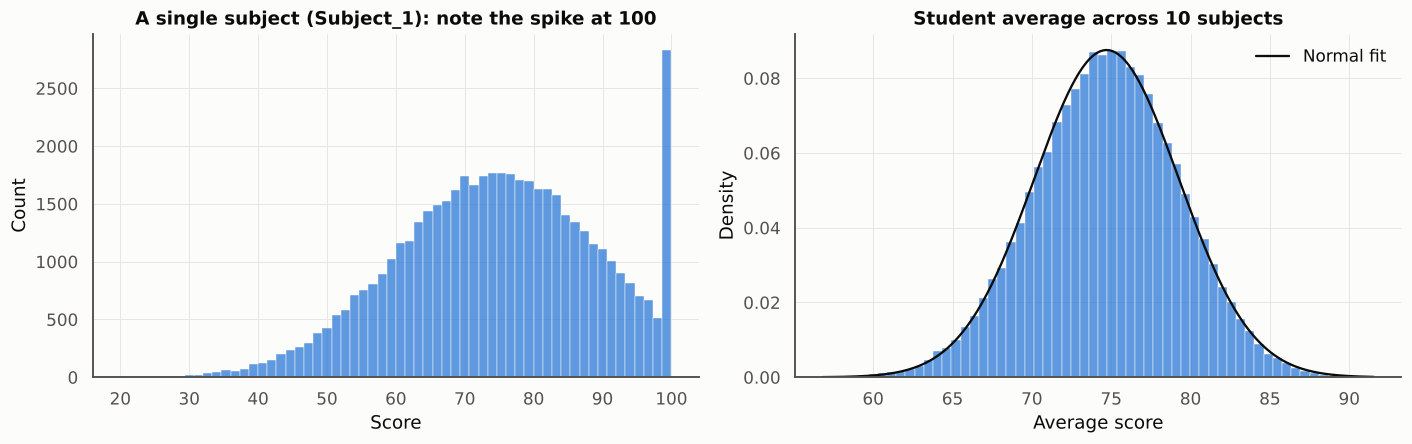

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(df["Subject_1"], bins=60, color=PALETTE[0], ax=axes[0], edgecolor="#fcfcfb", linewidth=0.3)
axes[0].set_title("A single subject (Subject_1): note the spike at 100")
axes[0].set_xlabel("Score")
sns.histplot(df["Average"], bins=60, color=PALETTE[0], ax=axes[1], edgecolor="#fcfcfb", linewidth=0.3, stat="density")
x = np.linspace(df["Average"].min(), df["Average"].max(), 300)
axes[1].plot(x, stats.norm.pdf(x, df["Average"].mean(), df["Average"].std()), color=INK, lw=1.5, label="Normal fit")
axes[1].set_title("Student average across 10 subjects")
axes[1].set_xlabel("Average score"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

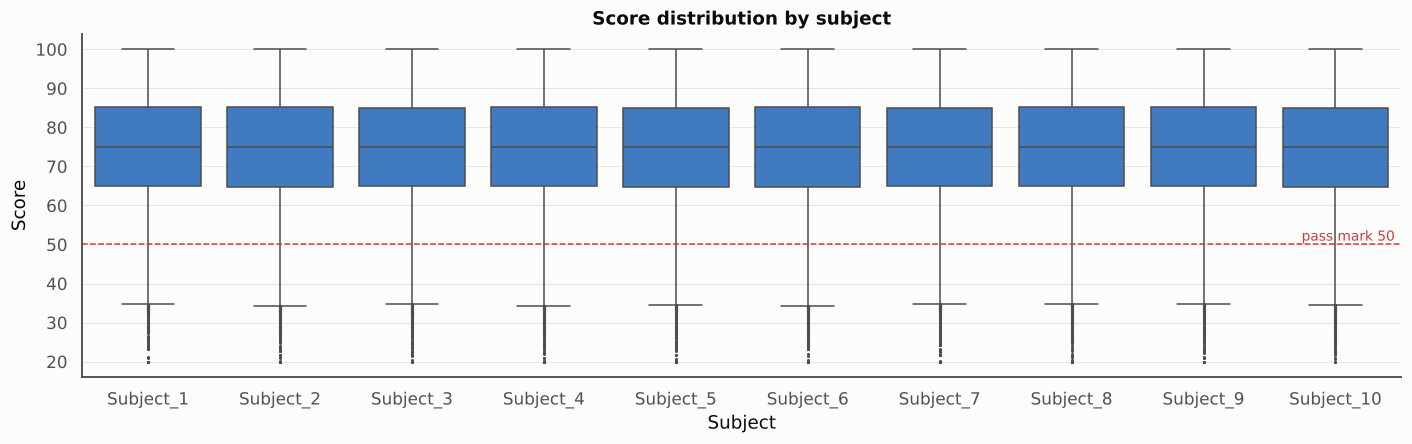

In [10]:
fig, ax = plt.subplots(figsize=(13, 4.2))
long = df[SUBJECTS].melt(var_name="Subject", value_name="Score")
sns.boxplot(data=long, x="Subject", y="Score", color=PALETTE[0], fliersize=1, linewidth=1, ax=ax)
ax.axhline(50, color="#d03b3b", ls="--", lw=1); ax.text(9.45, 51, "pass mark 50", color="#d03b3b", ha="right", fontsize=9)
ax.set_title("Score distribution by subject"); plt.tight_layout(); plt.show()

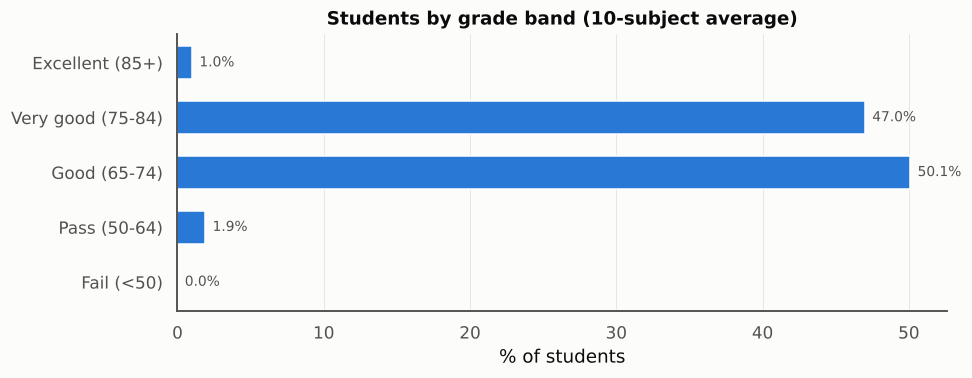

                   students      %
Band                              
Fail (<50)                0  0.000
Pass (50-64)            929  1.900
Good (65-74)          25052 50.100
Very good (75-84)     23504 47.000
Excellent (85+)         515  1.000

Students failing at least one subject: 38.5%
Mean number of subjects failed: 0.48


In [11]:
band_tbl = df["Band"].value_counts().reindex(labels)
band_pct = (band_tbl / len(df) * 100).round(1)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(labels, band_pct.values, color=PALETTE[0], height=0.6)
for i, v in enumerate(band_pct.values):
    ax.text(v + 0.5, i, f"{v}%", va="center", fontsize=9, color=INK2)
ax.set_xlabel("% of students"); ax.set_title("Students by grade band (10-subject average)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(pd.DataFrame({"students": band_tbl, "%": band_pct}))
print("\nStudents failing at least one subject: {:.1f}%".format((~df['Pass_all']).mean() * 100))
print("Mean number of subjects failed: {:.2f}".format(df['Subjects_failed'].mean()))

**Interpretation, univariate**
- Each subject averages about **74.7** (SD ≈ 14.4). The ten subjects are almost identical in centre and spread, so no subject stands out as harder or easier.
- The **10-subject average** is tightly concentrated (mean ≈ 74.7, SD ≈ 4.6) and close to normal. Averaging ten scores shrinks the SD by roughly √10, which is what you would expect if subject scores are **independent of each other** (tested in H7).
- **No student has a failing average**, and the large majority fall in the *Good* and *Very good* bands. At subject level, though, about **4–5% of individual scores are below 50**, and **nearly four in ten students (38.5%) fail at least one subject**. So failure is spread thinly across many students rather than concentrated in a weak group.
- The heavy spike at 100 confirms a **ceiling effect**: true performance above 100 was capped.

### 5.2 Demographics and structure

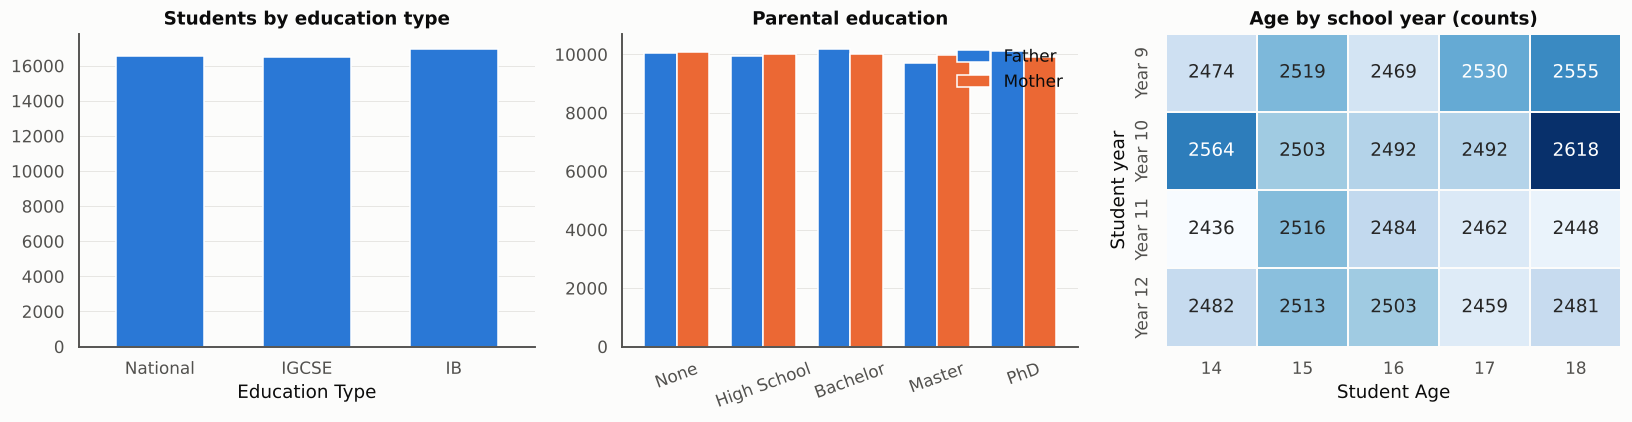

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["Education Type"].value_counts().reindex(EDU_ORDER).plot.bar(ax=axes[0], color=PALETTE[0], rot=0, width=0.6)
axes[0].set_title("Students by education type")
pd.DataFrame({"Father": df["Father Degree"].value_counts(), "Mother": df["Mother Degree"].value_counts()}).reindex(DEG_ORDER)\
  .plot.bar(ax=axes[1], color=PALETTE[:2], rot=20, width=0.75)
axes[1].set_title("Parental education"); axes[1].legend(frameon=False)
ct = pd.crosstab(df["Student year"], df["Student Age"])
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2], linewidths=1, linecolor="#fcfcfb")
axes[2].set_title("Age by school year (counts)")
for a in axes[:2]: a.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Interpretation.** The age-by-year heatmap is the most revealing exploratory chart. In a real school system the counts would cluster on a diagonal: most Year-9 students aged 14–15, most Year-12 students aged 17–18. Here, **every age is equally common in every year**. A 14-year-old is as likely to be in Year 12 as in Year 9. This is the first strong sign that the variables were **generated independently of one another** (Section 9).

### 5.3 Bivariate: performance by group

In [13]:
def group_summary(col):
    g = df.groupby(col, observed=True)["Average"]
    out = g.agg(n="count", mean="mean", sd="std", median="median")
    out["fail_any_%"] = df.groupby(col, observed=True)["Pass_all"].apply(lambda s: (~s).mean() * 100)
    out["excellent_%"] = df.groupby(col, observed=True)["Average"].apply(lambda s: (s >= 85).mean() * 100)
    return out

for col in ["Education Type", "Father Degree", "Mother Degree", "Parent_max_degree", "Student year", "Age_status"]:
    print(f"\n=== {col} ==="); print(group_summary(col).round(2).to_string())


=== Education Type ===
                    n   mean    sd  median  fail_any_%  excellent_%
Education Type                                                     
National        16545 74.740 4.530  74.780      38.090        0.910
IGCSE           16478 74.660 4.580  74.680      38.460        1.160
IB              16977 74.710 4.570  74.830      38.790        1.020

=== Father Degree ===
                   n   mean    sd  median  fail_any_%  excellent_%
Father Degree                                                     
None           10040 74.740 4.540  74.800      38.780        1.110
High School     9946 74.690 4.570  74.720      37.320        1.060
Bachelor       10197 74.720 4.550  74.850      39.580        0.900
Master          9718 74.670 4.540  74.690      38.240        1.100
PhD            10099 74.700 4.570  74.810      38.290        0.990

=== Mother Degree ===
                   n   mean    sd  median  fail_any_%  excellent_%
Mother Degree                                         

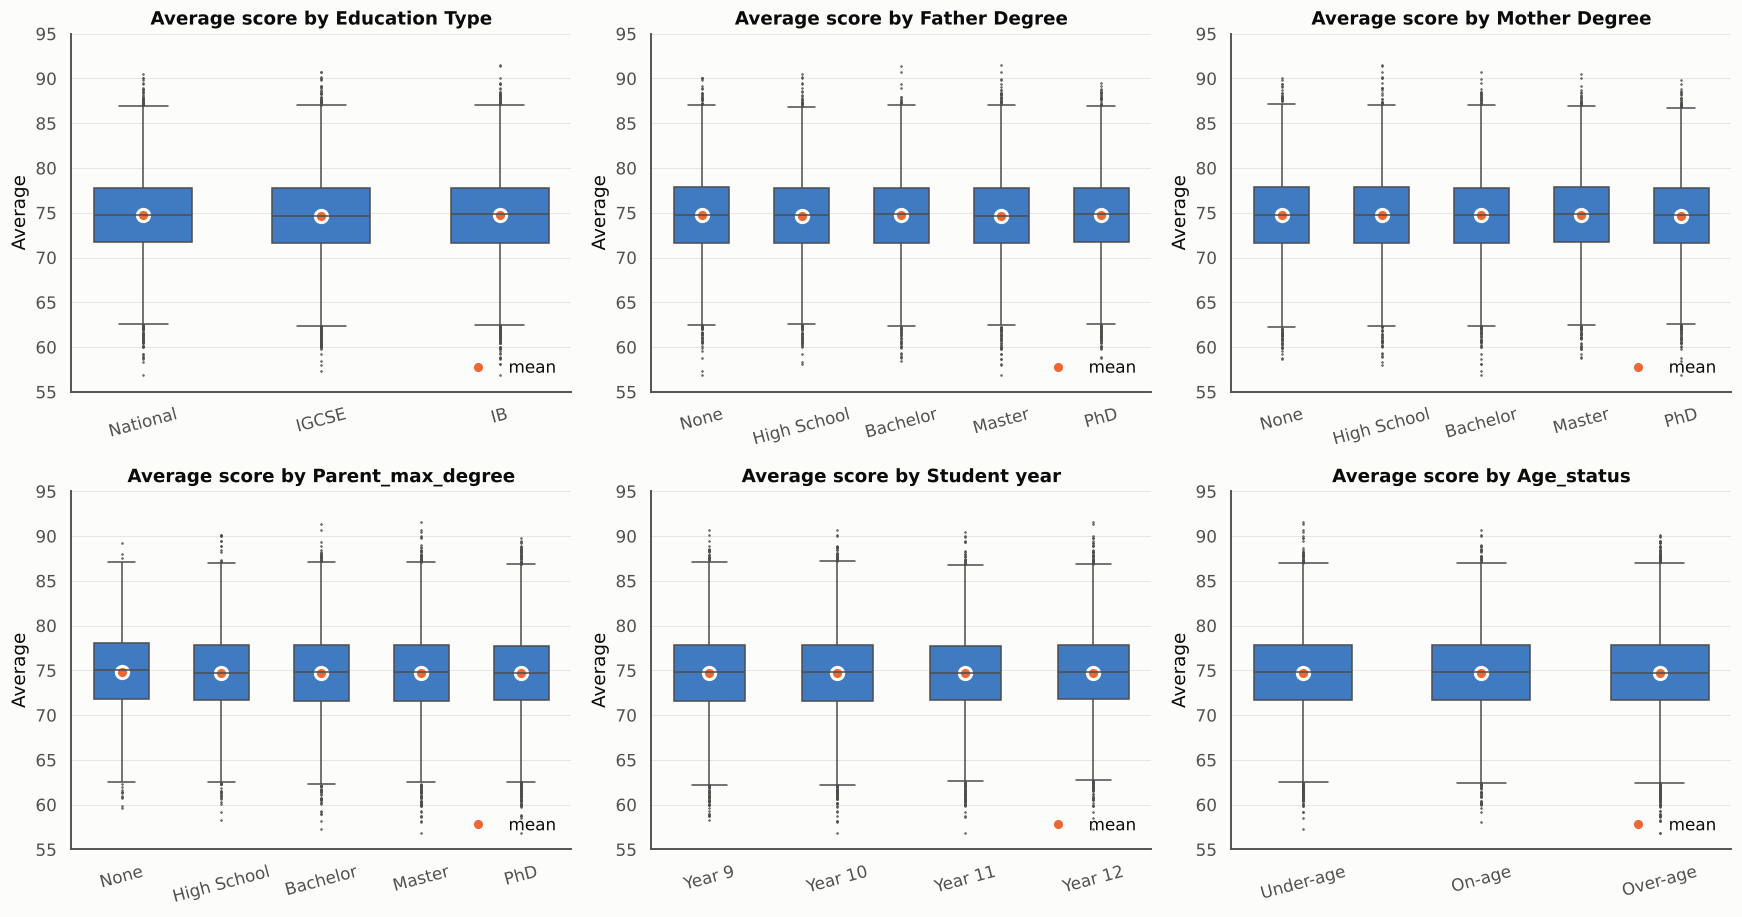

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
specs = [("Education Type", EDU_ORDER), ("Father Degree", DEG_ORDER), ("Mother Degree", DEG_ORDER),
         ("Parent_max_degree", DEG_ORDER), ("Student year", YEAR_ORDER), ("Age_status", ["Under-age", "On-age", "Over-age"])]
for ax, (col, order) in zip(axes.flat, specs):
    sns.boxplot(data=df, x=col, y="Average", order=order, color=PALETTE[0], fliersize=0.6, linewidth=1, ax=ax, width=0.55)
    means = df.groupby(col, observed=True)["Average"].mean().reindex(order)
    ax.plot(range(len(order)), means.values, "o", color=PALETTE[1], ms=8, mec="#fcfcfb", mew=2, label="mean")
    ax.set_title(f"Average score by {col}"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=15)
    ax.set_ylim(55, 95); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

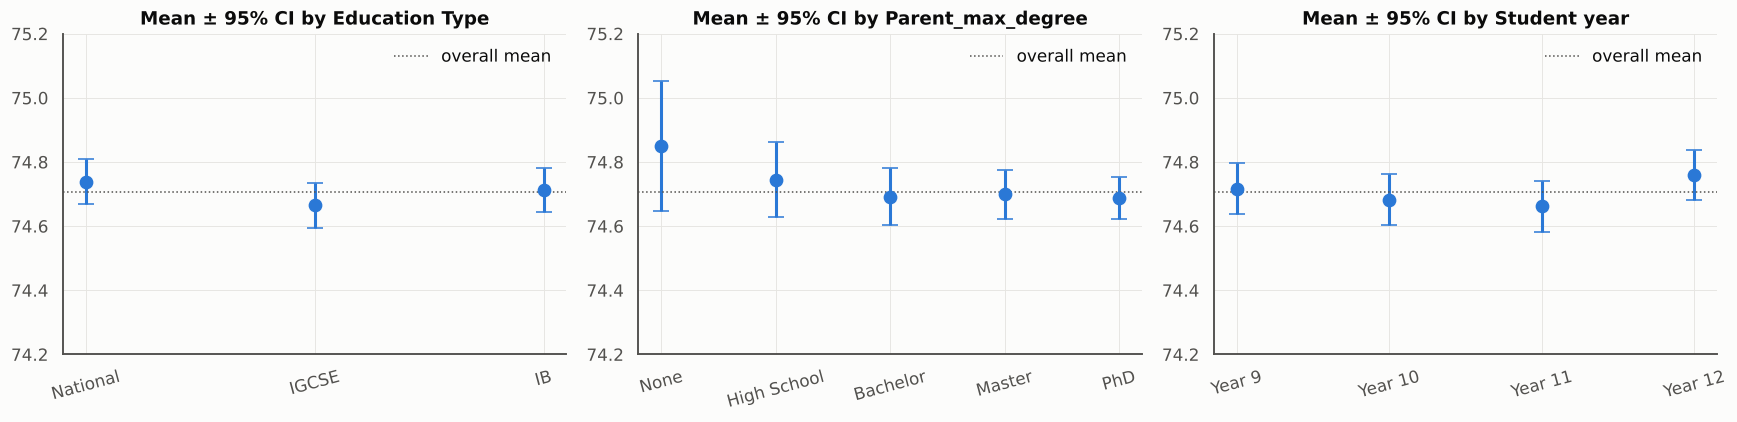

In [15]:
# Zoom in on the means with 95% confidence intervals - the honest scale for comparing groups
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, order) in zip(axes, [("Education Type", EDU_ORDER), ("Parent_max_degree", DEG_ORDER), ("Student year", YEAR_ORDER)]):
    g = df.groupby(col, observed=True)["Average"].agg(["mean", "sem"]).reindex(order)
    ax.errorbar(range(len(order)), g["mean"], yerr=1.96 * g["sem"], fmt="o", color=PALETTE[0], ms=8, capsize=5, lw=2)
    ax.axhline(df["Average"].mean(), color=INK2, ls=":", lw=1, label="overall mean")
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=15)
    ax.set_ylim(74.2, 75.2); ax.set_title(f"Mean ± 95% CI by {col}"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Interpretation, bivariate.** The boxplots for every grouping (track, father's, mother's or highest parental degree, year, age status) are **visually indistinguishable**. Zooming the y-axis to a one-point window shows the means differ by **less than 0.1 of a mark**, and every 95% confidence interval overlaps the overall mean. In practical terms, none of these factors appears to separate students. The formal tests in Section 7 check whether that impression holds.

### 5.4 Multivariate: relationships between subjects and access to tracks

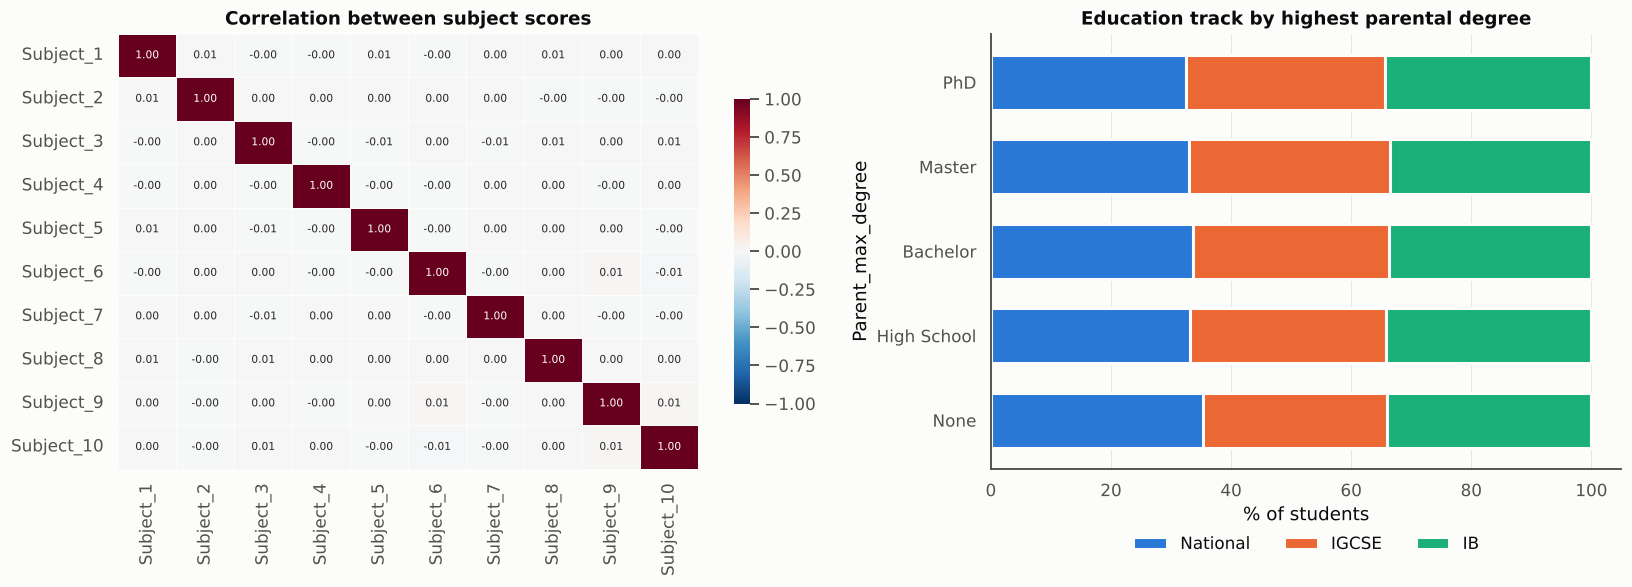

Education Type     National  IGCSE     IB
Parent_max_degree                        
None                 35.400 30.500 34.100
High School          33.100 32.700 34.200
Bachelor             33.700 32.600 33.700
Master               32.900 33.500 33.500
PhD                  32.600 33.100 34.300


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.15, 1]})
corr = df[SUBJECTS].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0],
            annot_kws={"size": 7}, linewidths=0.5, linecolor="#fcfcfb", cbar_kws={"shrink": .7})
axes[0].set_title("Correlation between subject scores")
share = pd.crosstab(df["Parent_max_degree"], df["Education Type"], normalize="index") * 100
share[EDU_ORDER].plot.barh(stacked=True, ax=axes[1], color=PALETTE[:3], width=0.65, edgecolor="#fcfcfb", linewidth=2)
axes[1].set_xlabel("% of students"); axes[1].set_title("Education track by highest parental degree")
axes[1].legend(title="", frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12)); axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(share.round(1))

**Interpretation, multivariate**
- **Subject correlations are effectively zero** (|r| < 0.02). In real school data, scores in mathematics, sciences and languages are typically **positively correlated** (r ≈ 0.4–0.7) because they share a common component: general ability, effort, school quality and home support. Here a student's score in one subject tells us nothing about their score in another.
- **Track enrolment shows no link to family background.** Children of parents with no qualification are as likely to be in IB (fee-paying, international) as children of PhD holders. In most countries IGCSE and IB schools charge substantial fees, so a strong socio-economic gradient would be expected.

## 6. Hypothesis development

Each hypothesis comes from the research questions and from what is commonly argued about secondary education systems. The significance level is **α = 0.05**. With n = 50,000, even tiny differences become "significant", so every test also reports an **effect size** (η², Cohen's d, Cramér's V or r) and judges *practical* importance, not just p-values.

| # | Null hypothesis (H₀) | Alternative (H₁) | Rationale | Test |
|---|---|---|---|---|
| **H1** | Mean average scores are equal across National, IGCSE and IB | At least one track differs | International tracks are often claimed to give better outcomes | One-way ANOVA, Welch ANOVA, Kruskal-Wallis, Tukey HSD, TOST equivalence |
| **H2** | Father's and mother's education are not associated with performance | Higher parental education → higher scores | Parental education is one of the strongest predictors of attainment worldwide | ANOVA + Spearman rank correlation |
| **H3** | First-generation students score the same as students with a university-educated parent | First-generation students score lower (one-sided) | The "first-generation gap" | Welch t-test (one-sided), Mann-Whitney U, Cohen's d |
| **H4** | Performance does not differ by school year | Performance changes with year | Learning progression / curriculum difficulty | ANOVA + Spearman |
| **H5** | Over-age students perform the same as on-age students | Over-age students perform worse (one-sided) | Over-age status often signals grade repetition | Welch t-test (one-sided), Cohen's d |
| **H6** | Education track is independent of parental education | Track depends on parental education | International schools are fee-paying, so access should follow socio-economic status | χ² test of independence, Cramér's V |
| **H7** | Subject scores are uncorrelated (the correlation matrix is an identity matrix) | Subject scores are correlated | A general academic-ability factor | Bartlett's test of sphericity, mean inter-subject r |
| **H8** | The share of students failing at least one subject is equal across tracks | The share differs | Equity of minimum standards | χ² test of independence |

## 7. Hypothesis testing
### 7.0 Helper functions and assumption checks

In [17]:
def eta_squared(groups):
    allv = np.concatenate(groups); gm = allv.mean()
    ssb = sum(len(g) * (g.mean() - gm) ** 2 for g in groups)
    sst = ((allv - gm) ** 2).sum()
    return ssb / sst

def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp

def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

def magnitude(value, kind):
    v = abs(value)
    cuts = {"eta2": (0.01, 0.06, 0.14), "d": (0.2, 0.5, 0.8), "r": (0.1, 0.3, 0.5), "V": (0.1, 0.3, 0.5)}[kind]
    return "negligible" if v < cuts[0] else "small" if v < cuts[1] else "medium" if v < cuts[2] else "large"

def anova_block(col, order):
    groups = [df.loc[df[col] == lvl, "Average"].values for lvl in order]
    F, p = stats.f_oneway(*groups)
    H, pk = stats.kruskal(*groups)
    lev = stats.levene(*groups)
    welch = sm.stats.anova_oneway(df["Average"], df[col].astype(str), use_var="unequal")
    e2 = eta_squared(groups)
    return {"F": F, "p_ANOVA": p, "Welch_F": welch.statistic, "p_Welch": welch.pvalue,
            "Kruskal_H": H, "p_Kruskal": pk, "Levene_p": lev.pvalue, "eta2": e2, "effect": magnitude(e2, "eta2")}

RESULTS = []   # collects every test for the final summary table
def record(h, test, stat, p, effect_name, effect, kind, decision=None):
    decision = decision or ("Reject H0" if p < ALPHA else "Fail to reject H0")
    RESULTS.append({"Hypothesis": h, "Test": test, "Statistic": stat, "p-value": p,
                    "Effect size": f"{effect_name} = {effect:.4f}", "Magnitude": magnitude(effect, kind), "Decision": decision})

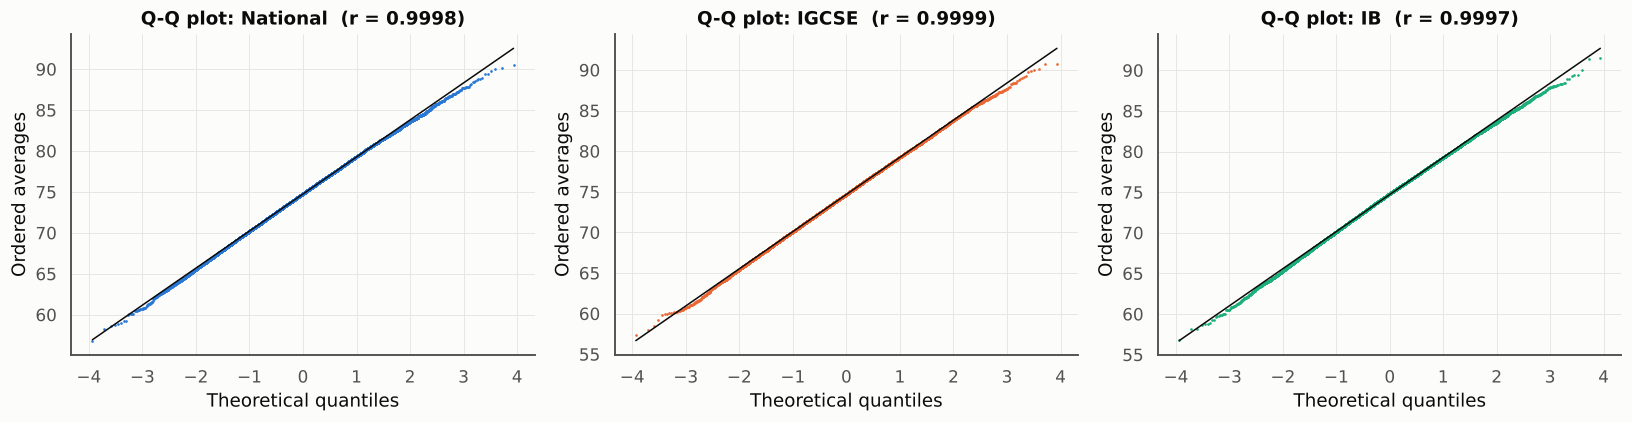

D'Agostino K² normality test on averages: K² = 47.72, p = 4.342e-11
Skew = -0.073, excess kurtosis = -0.041


In [18]:
# Normality: with n = 50,000 formal tests reject on trivial deviations, so we combine a test with a Q-Q plot.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lvl, c in zip(axes, EDU_ORDER, PALETTE):
    sample = df.loc[df["Education Type"] == lvl, "Average"]
    (osm, osr), (slope, inter, r) = stats.probplot(sample, dist="norm")
    ax.plot(osm, osr, ".", ms=1.5, color=c); ax.plot(osm, slope * osm + inter, color=INK, lw=1)
    ax.set_title(f"Q-Q plot: {lvl}  (r = {r:.4f})"); ax.set_xlabel("Theoretical quantiles"); ax.set_ylabel("Ordered averages")
plt.tight_layout(); plt.show()
k2, pn = stats.normaltest(df["Average"])
print(f"D'Agostino K² normality test on averages: K² = {k2:.2f}, p = {pn:.4g}")
print(f"Skew = {df['Average'].skew():.3f}, excess kurtosis = {df['Average'].kurt():.3f}")

**Assumption check.** The Q-Q plots are almost perfectly straight (r ≈ 1), and skew and kurtosis are close to 0. Any formal rejection of normality reflects the huge sample, not a meaningful departure, and with n > 16,000 per group the Central Limit Theorem makes ANOVA and t-tests robust anyway. As a safeguard, each parametric test is paired with a **non-parametric** alternative (Kruskal-Wallis / Mann-Whitney) and a **Welch** version that does not assume equal variances.

### 7.1 H1: Does performance differ by education type?

In [19]:
r1 = anova_block("Education Type", EDU_ORDER)
pd.Series(r1).to_frame("H1: Education Type").T

,F,p_ANOVA,Welch_F,p_Welch,Kruskal_H,p_Kruskal,Levene_p,eta2,effect
H1: Education Type,1.122,0.325,1.123,0.325,3.283,0.194,0.465,0.000,negligible


In [20]:
tuk = pairwise_tukeyhsd(df["Average"], df["Education Type"].astype(str), alpha=ALPHA)
print(tuk.summary())

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1  group2  meandiff p-adj   lower  upper  reject
-----------------------------------------------------
    IB    IGCSE  -0.0475 0.6066 -0.1643 0.0693  False
    IB National   0.0267 0.8536   -0.09 0.1434  False
 IGCSE National   0.0742 0.3011 -0.0434 0.1917  False
-----------------------------------------------------


In [21]:
# Equivalence test (TOST): are the tracks equivalent within +/-1 mark? A non-significant ANOVA alone cannot prove
# "no difference"; TOST checks whether any real difference is smaller than a margin judged educationally trivial.
from statsmodels.stats.weightstats import ttost_ind
MARGIN = 1.0
rows = []
for a, b in [("National", "IGCSE"), ("National", "IB"), ("IGCSE", "IB")]:
    xa = df.loc[df["Education Type"] == a, "Average"]; xb = df.loc[df["Education Type"] == b, "Average"]
    p_tost, _, _ = ttost_ind(xa, xb, -MARGIN, MARGIN, usevar="unequal")
    rows.append({"Comparison": f"{a} vs {b}", "Mean diff": xa.mean() - xb.mean(), "Cohen's d": cohens_d(xa, xb),
                 "TOST p": p_tost, "Equivalent within ±1 mark?": p_tost < ALPHA})
pd.DataFrame(rows)

,Comparison,Mean diff,Cohen's d,TOST p,Equivalent within ±1 mark?
0,National vs IGCSE,0.074,0.016,0.000,True
1,National vs IB,0.027,0.006,0.000,True
2,IGCSE vs IB,-0.047,-0.010,0.000,True


In [22]:
power = FTestAnovaPower().solve_power(effect_size=0.02, nobs=len(df), alpha=ALPHA, k_groups=3)
print(f"Power to detect even a very small effect (Cohen's f = 0.02) with n = {len(df):,}: {power:.3f}")
record("H1", "One-way ANOVA (track)", f"F = {r1['F']:.3f}", r1["p_ANOVA"], "η²", r1["eta2"], "eta2")

Power to detect even a very small effect (Cohen's f = 0.02) with n = 50,000: 0.985


**H1 interpretation.** The ANOVA, Welch ANOVA and Kruskal-Wallis tests all fail to reject H₀ (p > 0.05). Tukey HSD finds no pair of tracks that differs significantly. The effect size is η² ≈ 0.00005: education type explains **less than one-hundredth of one percent** of the variation in student averages. The **TOST equivalence test** goes further and shows that every pair of tracks is *statistically equivalent* within ±1 mark. The power analysis shows the study had about 98.5% power to detect even a very small effect (Cohen's f = 0.02), so this is not a "we couldn't see it" result. **Conclusion:** in this dataset, National, IGCSE and IB students perform the same.

### 7.2 H2: Is parental education associated with performance?

In [23]:
h2 = {}
for col, rank in [("Father Degree", "Father_rank"), ("Mother Degree", "Mother_rank"), ("Parent_max_degree", "Parent_max_rank")]:
    res = anova_block(col, DEG_ORDER)
    rho, prho = stats.spearmanr(df[rank], df["Average"])
    res.update({"Spearman_rho": rho, "p_Spearman": prho})
    h2[col] = res
h2 = pd.DataFrame(h2).T
h2[["F", "p_ANOVA", "Kruskal_H", "p_Kruskal", "eta2", "Spearman_rho", "p_Spearman", "effect"]]

,F,p_ANOVA,Kruskal_H,p_Kruskal,eta2,Spearman_rho,p_Spearman,effect
Father Degree,0.395,0.813,2.150,0.708,0.000,-0.001,0.754,negligible
Mother Degree,0.328,0.860,1.819,0.769,0.000,-0.002,0.638,negligible
Parent_max_degree,0.708,0.586,3.227,0.521,0.000,-0.004,0.335,negligible


In [24]:
# Does the effect of one parent depend on the other? Two-way ANOVA with interaction.
m2 = smf.ols("Average ~ C(Q('Father Degree')) * C(Q('Mother Degree'))", data=df.assign(**{
    "Father Degree": df["Father Degree"].astype(str), "Mother Degree": df["Mother Degree"].astype(str)})).fit()
aov2 = sm.stats.anova_lm(m2, typ=2); aov2["eta2_partial"] = aov2["sum_sq"] / (aov2["sum_sq"] + aov2.loc["Residual", "sum_sq"])
aov2

,sum_sq,df,F,PR(>F),eta2_partial
C(Q('Father Degree')),33.227,4.000,0.400,0.809,0.000
C(Q('Mother Degree')),27.658,4.000,0.333,0.856,0.000
C(Q('Father Degree')):C(Q('Mother Degree')),335.848,16.000,1.011,0.441,0.000
Residual,1037791.760,49975.000,NaN,NaN,0.500


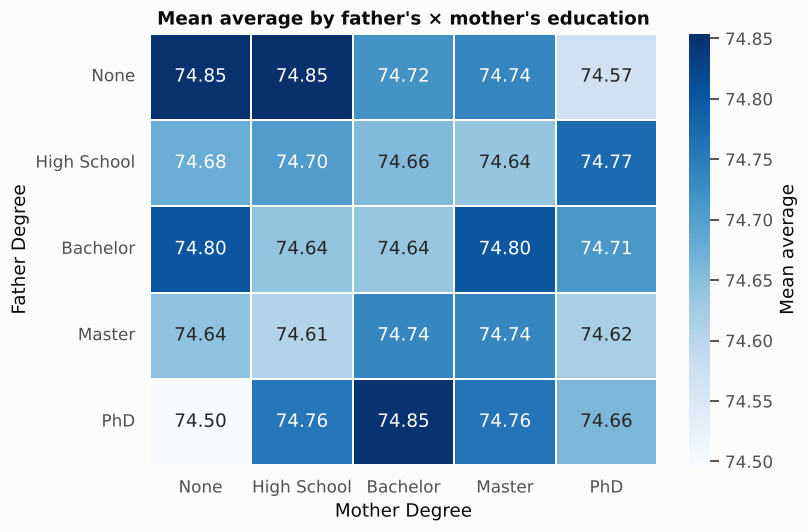

In [25]:
piv = df.pivot_table(index="Father Degree", columns="Mother Degree", values="Average", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.heatmap(piv, annot=True, fmt=".2f", cmap="Blues", ax=ax, linewidths=1, linecolor="#fcfcfb", cbar_kws={"label": "Mean average"})
ax.set_title("Mean average by father's × mother's education"); plt.tight_layout(); plt.show()
for col, rank in [("Father Degree", "Father_rank"), ("Mother Degree", "Mother_rank")]:
    r = h2.loc[col]
    record("H2", f"ANOVA + Spearman ({col})", f"F = {r['F']:.3f}; ρ = {r['Spearman_rho']:.4f}", r["p_ANOVA"], "η²", r["eta2"], "eta2")

**H2 interpretation.** Neither father's nor mother's education, nor the higher of the two, is associated with student performance. The ANOVA and Kruskal-Wallis p-values exceed 0.05, the Spearman correlations are about 0.00, and η² is below 0.0002. The two-way ANOVA shows **no interaction**, and the father × mother heatmap varies within roughly ±0.3 of a mark with no gradient. **We fail to reject H₀.** This contrasts sharply with the international evidence (PISA, TIMSS and PIRLS), where parental education is consistently one of the strongest predictors of achievement.

### 7.3 H3: Do first-generation students score lower?

In [26]:
fg  = df.loc[df["First_generation"], "Average"]
ngf = df.loc[~df["First_generation"], "Average"]
t, p_two = stats.ttest_ind(fg, ngf, equal_var=False)
p_one = p_two / 2 if t < 0 else 1 - p_two / 2          # H1: first-gen mean < others
u, p_u = stats.mannwhitneyu(fg, ngf, alternative="less")
d = cohens_d(fg, ngf)
ci = stats.ttest_ind(fg, ngf, equal_var=False).confidence_interval(0.95)
print(f"First-generation students: n = {len(fg):,}, mean = {fg.mean():.3f}")
print(f"University-educated parent: n = {len(ngf):,}, mean = {ngf.mean():.3f}")
print(f"Difference = {fg.mean() - ngf.mean():.3f}  (95% CI {ci.low:.3f} to {ci.high:.3f})")
print(f"Welch t = {t:.3f}, one-sided p = {p_one:.4f}  |  Mann-Whitney U one-sided p = {p_u:.4f}  |  Cohen's d = {d:.4f}")
print("Power to detect a gap of d = 0.05:", round(TTestIndPower().solve_power(-0.05, nobs1=len(fg), ratio=len(ngf) / len(fg), alpha=ALPHA, alternative="smaller"), 3))
record("H3", "Welch t-test, one-sided (first-gen < others)", f"t = {t:.3f}", p_one, "Cohen's d", d, "d")

First-generation students: n = 7,924, mean = 74.771
University-educated parent: n = 42,076, mean = 74.693
Difference = 0.078  (95% CI -0.031 to 0.188)
Welch t = 1.399, one-sided p = 0.9191  |  Mann-Whitney U one-sided p = 0.8765  |  Cohen's d = 0.0172
Power to detect a gap of d = 0.05: 0.993


**H3 interpretation.** About 16% of students (7,924) are first-generation: neither parent holds a degree beyond high school. Their mean average (74.77) is practically identical to that of peers with a university-educated parent. The difference is under a tenth of a mark and, if anything, slightly in their favour; the 95% confidence interval straddles zero, Cohen's d ≈ 0, and the one-sided test is not significant. **We fail to reject H₀:** the dataset shows **no first-generation disadvantage**.

### 7.4 H4: Does performance change across school years?

In [27]:
r4 = anova_block("Student year", YEAR_ORDER)
rho4, p4 = stats.spearmanr(df["Year_num"], df["Average"])
r4.update({"Spearman_rho": rho4, "p_Spearman": p4})
record("H4", "One-way ANOVA (school year)", f"F = {r4['F']:.3f}", r4["p_ANOVA"], "η²", r4["eta2"], "eta2")
pd.Series(r4).to_frame("H4: Student year").T

,F,p_ANOVA,Welch_F,p_Welch,Kruskal_H,p_Kruskal,Levene_p,eta2,effect,Spearman_rho,p_Spearman
H4: Student year,1.085,0.354,1.104,0.346,2.634,0.452,0.002,0.000,negligible,0.002,0.728


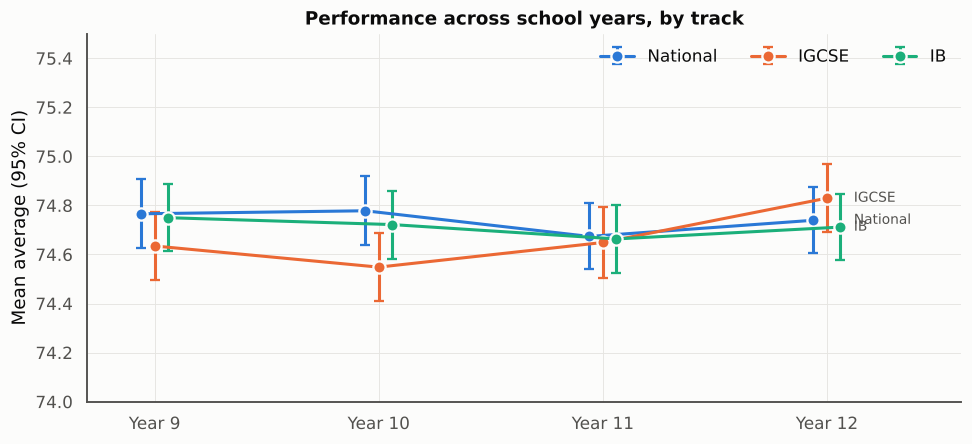

In [28]:
yr = df.groupby(["Student year", "Education Type"], observed=True)["Average"].agg(["mean", "sem"]).reset_index()
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lvl in enumerate(EDU_ORDER):
    s = yr[yr["Education Type"] == lvl]
    ax.errorbar(np.arange(4) + (i - 1) * 0.06, s["mean"], yerr=1.96 * s["sem"], marker="o", ms=8, lw=2, capsize=3,
                color=PALETTE[i], label=lvl, mec="#fcfcfb", mew=1.5)
    ax.text(3.12, s["mean"].iloc[-1], lvl, color=INK2, va="center", fontsize=9)
ax.set_xticks(range(4)); ax.set_xticklabels(YEAR_ORDER); ax.set_xlim(-0.3, 3.6); ax.set_ylim(74, 75.5)
ax.set_ylabel("Mean average (95% CI)"); ax.set_title("Performance across school years, by track"); ax.legend(frameon=False, ncol=3)
plt.tight_layout(); plt.show()

**H4 interpretation.** There is no significant difference across Years 9–12 (ANOVA p > 0.05, η² ≈ 0, Spearman ρ ≈ 0), and the tracks follow no consistent trajectory: the lines cross at random inside overlapping confidence intervals. **We fail to reject H₀.** Scores neither rise as students gain experience nor fall as the curriculum gets harder.

### 7.5 H5: Do over-age students perform worse?

In [29]:
print(df["Age_status"].value_counts().to_string(), "\n")
over = df.loc[df["Age_status"] == "Over-age", "Average"]; on = df.loc[df["Age_status"] == "On-age", "Average"]
t5, p5_two = stats.ttest_ind(over, on, equal_var=False)
p5 = p5_two / 2 if t5 < 0 else 1 - p5_two / 2
d5 = cohens_d(over, on)
r_gap, p_gap = stats.pearsonr(df["Age_gap"], df["Average"])
print(f"Over-age mean = {over.mean():.3f}, on-age mean = {on.mean():.3f}")
print(f"Welch t = {t5:.3f}, one-sided p = {p5:.4f}, Cohen's d = {d5:.4f}")
print(f"Correlation between age gap and average: r = {r_gap:.4f}, p = {p_gap:.4f}")
record("H5", "Welch t-test, one-sided (over-age < on-age)", f"t = {t5:.3f}", p5, "Cohen's d", d5, "d")

Age_status
Over-age     25066
Under-age    15014
On-age        9920 

Over-age mean = 74.700, on-age mean = 74.712
Welch t = -0.222, one-sided p = 0.4122, Cohen's d = -0.0026
Correlation between age gap and average: r = 0.0005, p = 0.9156


**H5 interpretation.** Only about 20% of students are the expected age for their year; 50% are over-age and 30% under-age. That alone would be remarkable: in reality it would point to widespread repetition or irregular entry. Yet over-age students perform the same as on-age students (Cohen's d ≈ 0, not significant), and the age gap is uncorrelated with performance. **We fail to reject H₀.** In most systems, over-age status is a well-documented risk marker for low attainment.

### 7.6 H6: Is access to education tracks related to family background?

In [30]:
ct6 = pd.crosstab(df["Parent_max_degree"], df["Education Type"])
chi2, p6, dof, exp = stats.chi2_contingency(ct6)
V6 = cramers_v(ct6)
print(ct6, "\n")
print(f"χ² = {chi2:.3f}, df = {dof}, p = {p6:.4f}, Cramér's V = {V6:.4f}")
resid = (ct6 - exp) / np.sqrt(exp)
print("\nStandardised residuals (|value| > 2 would flag over/under-representation):"); print(resid.round(2))
record("H6", "χ² independence (parent degree × track)", f"χ² = {chi2:.3f}", p6, "Cramér's V", V6, "V")

Education Type     National  IGCSE    IB
Parent_max_degree                       
None                    713    614   687
High School            1958   1933  2019
Bachelor               3445   3325  3442
Master                 4555   4634  4638
PhD                    5874   5972  6191 

χ² = 13.576, df = 8, p = 0.0935, Cramér's V = 0.0117

Standardised residuals (|value| > 2 would flag over/under-representation):
Education Type     National  IGCSE     IB
Parent_max_degree                        
None                  1.800 -1.930  0.120
High School           0.050 -0.330  0.270
Bachelor              1.130 -0.700 -0.430
Master               -0.300  1.140 -0.830
PhD                  -1.220  0.360  0.850


In [31]:
for col in ["Father Degree", "Mother Degree"]:
    c = pd.crosstab(df[col], df["Education Type"]); ch, pp, _, _ = stats.chi2_contingency(c)
    print(f"{col} × Education Type: χ² = {ch:.2f}, p = {pp:.4f}, V = {cramers_v(c):.4f}")

Father Degree × Education Type: χ² = 3.94, p = 0.8629, V = 0.0063
Mother Degree × Education Type: χ² = 7.20, p = 0.5151, V = 0.0085


**H6 interpretation.** The χ² test does not reject independence (Cramér's V ≈ 0.01, and every standardised residual sits well within ±2). Children from every family-education level are spread evenly across National, IGCSE and IB. **We fail to reject H₀.** In practice, IGCSE and IB enrolment is usually concentrated in urban, higher-income families, so a strong association would be expected. Its absence is a major warning sign about how representative the data are.

### 7.7 H7: Are subject scores correlated (a general-ability factor)?

In [32]:
R = df[SUBJECTS].corr().values; n, p = len(df), len(SUBJECTS)
bart_chi2 = -(n - 1 - (2 * p + 5) / 6) * np.log(np.linalg.det(R))
bart_df = p * (p - 1) / 2
bart_p = stats.chi2.sf(bart_chi2, bart_df)
off = R[np.triu_indices(p, 1)]
print(f"Bartlett's test of sphericity: χ² = {bart_chi2:.2f}, df = {bart_df:.0f}, p = {bart_p:.4g}")
print(f"Mean inter-subject r = {off.mean():.4f}; range {off.min():.4f} to {off.max():.4f}")
eig = np.linalg.eigvalsh(R)[::-1]
print("Variance explained by 1st principal component: {:.1f}% (pure noise would give ~{:.1f}%)".format(eig[0] / p * 100, 100 / p))
record("H7", "Bartlett's sphericity (subject correlations)", f"χ² = {bart_chi2:.2f}", bart_p, "mean r", off.mean(), "r",
       decision=("Reject H0" if bart_p < ALPHA else "Fail to reject H0"))

Bartlett's test of sphericity: χ² = 43.45, df = 45, p = 0.5378
Mean inter-subject r = 0.0008; range -0.0123 to 0.0097
Variance explained by 1st principal component: 10.2% (pure noise would give ~10.0%)


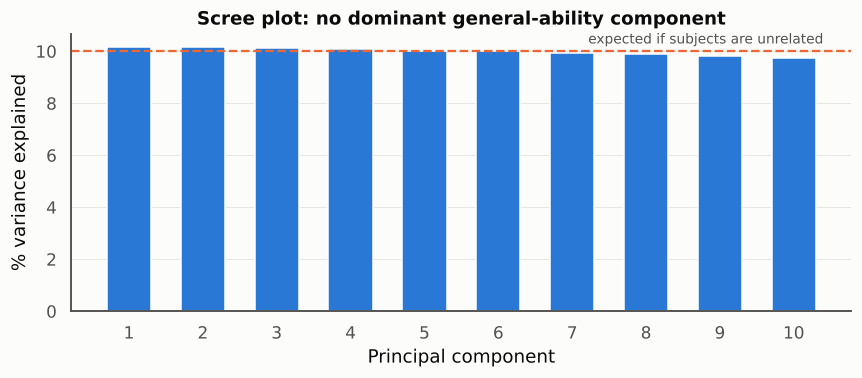

In [33]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(1, p + 1), eig / p * 100, color=PALETTE[0], width=0.6)
ax.axhline(100 / p, color=PALETTE[1], ls="--", lw=1.5); ax.text(10.4, 100 / p + 0.3, "expected if subjects are unrelated", ha="right", color=INK2, fontsize=9)
ax.set_xticks(range(1, p + 1)); ax.set_xlabel("Principal component"); ax.set_ylabel("% variance explained")
ax.set_title("Scree plot: no dominant general-ability component"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**H7 interpretation.** Bartlett's test **does not reject sphericity** (p ≈ 0.54), even at n = 50,000. The **mean inter-subject correlation is about 0.00** and the first principal component explains about 10%, exactly what ten unrelated variables would produce. The scree plot is flat. In practice, **there is no general academic-ability factor**: doing well in one subject says nothing about another. In real assessment data this finding would be almost unheard of.

### 7.8 H8: Does the rate of failing at least one subject differ by track?

In [34]:
ct8 = pd.crosstab(df["Education Type"], df["Pass_all"].map({True: "Passed all", False: "Failed ≥1"}))
chi8, p8, _, _ = stats.chi2_contingency(ct8)
V8 = cramers_v(ct8)
print(ct8.assign(**{"fail_rate_%": ct8["Failed ≥1"] / ct8.sum(axis=1) * 100}).round(2))
print(f"\nχ² = {chi8:.3f}, p = {p8:.4f}, Cramér's V = {V8:.4f}")
record("H8", "χ² independence (track × failed ≥1 subject)", f"χ² = {chi8:.3f}", p8, "Cramér's V", V8, "V")

Pass_all        Failed ≥1  Passed all  fail_rate_%
Education Type                                    
National             6302       10243       38.090
IGCSE                6338       10140       38.460
IB                   6585       10392       38.790

χ² = 1.725, p = 0.4220, Cramér's V = 0.0059


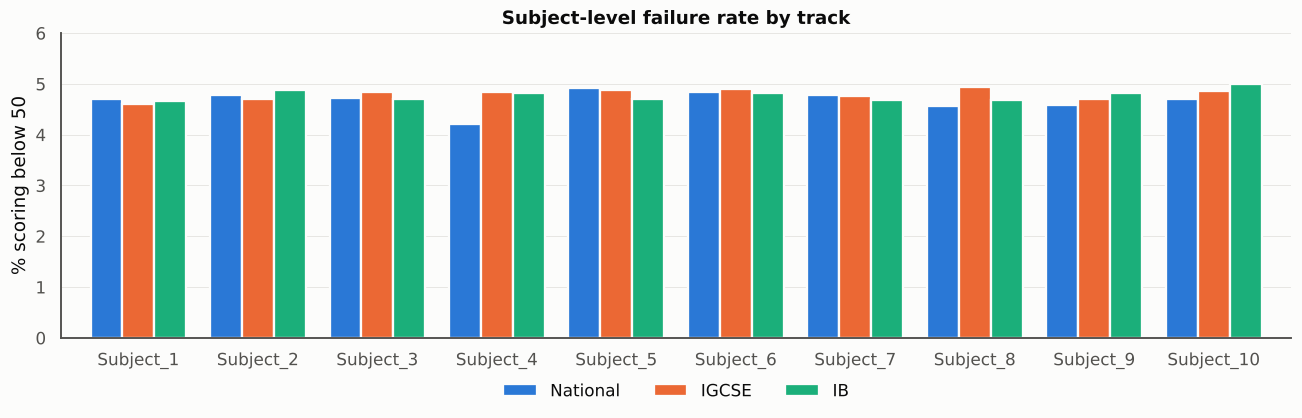

In [35]:
fail_by = (df.groupby("Education Type", observed=True)[SUBJECTS].apply(lambda g: (g < 50).mean() * 100)).T
fig, ax = plt.subplots(figsize=(12, 4))
fail_by[EDU_ORDER].plot.bar(ax=ax, color=PALETTE[:3], width=0.8, edgecolor="#fcfcfb", linewidth=1.5, rot=0)
ax.set_ylabel("% scoring below 50"); ax.set_title("Subject-level failure rate by track"); ax.set_ylim(0, 6)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

**H8 interpretation.** About 38–39% of students in every track fail at least one subject, and the χ² test shows no difference between tracks (Cramér's V ≈ 0.01). Subject-by-subject failure rates are also flat across tracks. **We fail to reject H₀.** Minimum-standard outcomes are the same whichever curriculum a student follows.

## 8. Multivariate model: OLS regression
All predictors are combined in one model to check whether any effect appears once the others are held constant.

In [36]:
mdl_df = df.assign(Edu=df["Education Type"].astype(str), Father=df["Father Degree"].astype(str),
                   Mother=df["Mother Degree"].astype(str), Year=df["Student year"].astype(str), Age=df["Student Age"])
ols = smf.ols("Average ~ C(Edu, Treatment('National')) + C(Father, Treatment('None')) + "
              "C(Mother, Treatment('None')) + C(Year, Treatment('Year 9')) + Age", data=mdl_df).fit(cov_type="HC3")
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                Average   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.6307
Date:                Wed, 18 Nov 2026   Prob (F-statistic):              0.842
Time:                        23:24:37   Log-Likelihood:            -1.4677e+05
No. Observations:               50000   AIC:                         2.936e+05
Df Residuals:                   49985   BIC:                         2.937e+05
Df Model:                          14                                         
Covariance Type:                  HC3                                         
                                                  coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------

R² = 0.00018  ->  the model explains 0.018% of the variation in student averages
Overall model F-test p-value = 0.8418


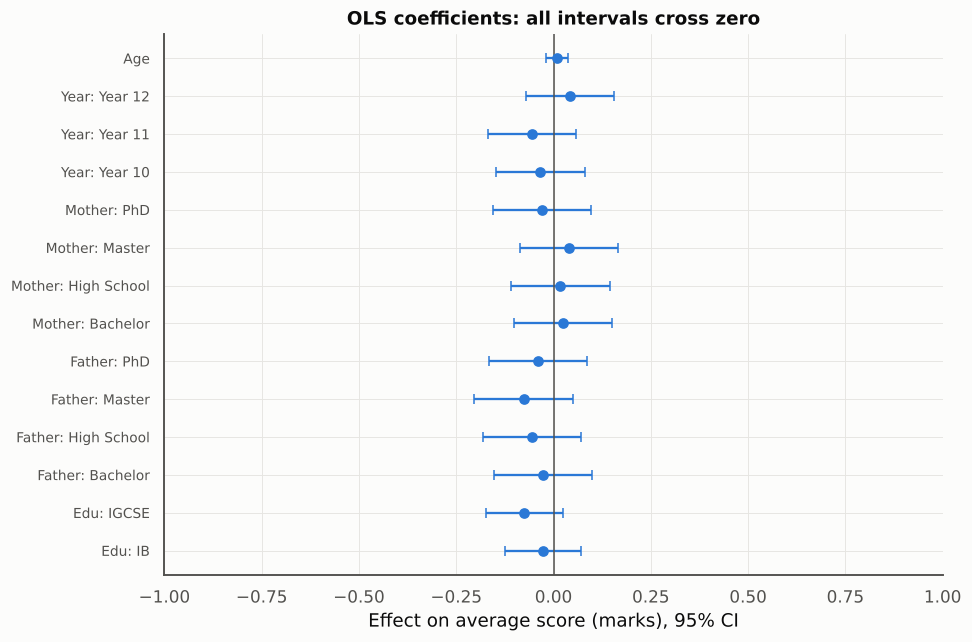

In [37]:
print(f"R² = {ols.rsquared:.5f}  ->  the model explains {ols.rsquared * 100:.3f}% of the variation in student averages")
print(f"Overall model F-test p-value = {ols.f_pvalue:.4f}")
coefs = ols.params.drop("Intercept"); cis = ols.conf_int().drop("Intercept")
fig, ax = plt.subplots(figsize=(9, 6))
yy = np.arange(len(coefs))
ax.errorbar(coefs.values, yy, xerr=[coefs - cis[0], cis[1] - coefs], fmt="o", color=PALETTE[0], capsize=3, ms=6)
ax.axvline(0, color=INK2, lw=1)
nice = [c.replace("C(", "").replace(", Treatment('National'))", "").replace(", Treatment('None'))", "")
         .replace(", Treatment('Year 9'))", "").replace("[T.", ": ").replace("]", "") for c in coefs.index]
ax.set_yticks(yy); ax.set_yticklabels(nice, fontsize=9); ax.set_xlim(-1, 1)
ax.set_xlabel("Effect on average score (marks), 95% CI"); ax.set_title("OLS coefficients: all intervals cross zero")
plt.tight_layout(); plt.show()

**Model interpretation.** Taken together, track, both parents' education, year and age explain **essentially 0%** of the variation in scores (R² ≈ 0.0002, i.e. 0.02%). The overall F-test is not significant, and every coefficient's 95% confidence interval crosses zero and stays within about ±0.3 of a mark. The variation in student performance in this dataset is **entirely unexplained by the variables recorded**.

## 9. Data-credibility assessment

A good analyst asks not only *what the data say* but *whether the data can say it*. Several features together strongly suggest that this dataset is **synthetic, generated by independent random draws**, rather than a record of real students:

In [38]:
checks = pd.DataFrame([
    ["Age vs year", "Strong diagonal (r ≈ 0.8+)", f"r = {stats.pearsonr(df['Student Age'], df['Year_num'])[0]:.3f}", "Age drawn independently of year"],
    ["Inter-subject correlation", "r ≈ 0.4-0.7", f"mean r = {off.mean():.3f}", "Each subject drawn independently"],
    ["Track × family background", "Strong gradient (private fees)", f"Cramér's V = {V6:.3f}", "Track assigned at random"],
    ["Category balance", "Uneven (national track is the large majority)", f"track shares = {(df['Education Type'].value_counts(normalize=True)*100).round(1).to_dict()}", "Uniform sampling"],
    ["Parental education", "Skewed (PhD rare)", f"PhD fathers = {(df['Father Degree']=='PhD').mean()*100:.1f}%", "Uniform sampling"],
    ["Score distribution", "Varies by subject", "Every subject ≈ N(75, 15), clipped to [20, 100]", "Identical generating distribution"],
], columns=["Feature", "Expected in real school data", "Observed", "Most likely explanation"])
checks

,Feature,Expected in real school data,Observed,Most likely explanation
0,Age vs year,Strong diagonal (r ≈ 0.8+),r = -0.005,Age drawn independently of year
1,Inter-subject correlation,r ≈ 0.4-0.7,mean r = 0.001,Each subject drawn independently
2,Track × family background,Strong gradient (private fees),Cramér's V = 0.012,Track assigned at random
3,Category balance,Uneven (national track is the large majority),"track shares = {'IB': 34.0, 'National': 33.1, ...",Uniform sampling
4,Parental education,Skewed (PhD rare),PhD fathers = 20.2%,Uniform sampling
5,Score distribution,Varies by subject,"Every subject ≈ N(75, 15), clipped to [20, 100]",Identical generating distribution


Two context points support this reading:
- In most countries, **the large majority of secondary students follow the national track**, while IGCSE and IB serve a small fee-paying minority. An even three-way split is not realistic.
- In any national population the share of adults holding a **PhD is very small**, yet here about 20% of fathers and 20% of mothers hold one.

**What this means:** the null results above are *internally valid*. The tests are correct and properly powered, and they faithfully describe this dataset. They are **not** evidence about real students. They are what independent random variables are expected to produce. That is a valuable lesson in its own right: careful EDA should come before any policy claim.

## 10. Summary of hypothesis tests

In [39]:
summary = pd.DataFrame(RESULTS)
summary["p-value"] = summary["p-value"].map(lambda v: f"{v:.4f}")
summary

,Hypothesis,Test,Statistic,p-value,Effect size,Magnitude,Decision
0,H1,One-way ANOVA (track),F = 1.122,0.3255,η² = 0.0000,negligible,Fail to reject H0
1,H2,ANOVA + Spearman (Father Degree),F = 0.395; ρ = -0.0014,0.8126,η² = 0.0000,negligible,Fail to reject H0
2,H2,ANOVA + Spearman (Mother Degree),F = 0.328; ρ = -0.0021,0.8596,η² = 0.0000,negligible,Fail to reject H0
3,H3,"Welch t-test, one-sided (first-gen < others)",t = 1.399,0.9191,Cohen's d = 0.0172,negligible,Fail to reject H0
4,H4,One-way ANOVA (school year),F = 1.085,0.3541,η² = 0.0001,negligible,Fail to reject H0
5,H5,"Welch t-test, one-sided (over-age < on-age)",t = -0.222,0.4122,Cohen's d = -0.0026,negligible,Fail to reject H0
6,H6,χ² independence (parent degree × track),χ² = 13.576,0.0935,Cramér's V = 0.0117,negligible,Fail to reject H0
7,H7,Bartlett's sphericity (subject correlations),χ² = 43.45,0.5378,mean r = 0.0008,negligible,Fail to reject H0
8,H8,χ² independence (track × failed ≥1 subject),χ² = 1.725,0.4220,Cramér's V = 0.0059,negligible,Fail to reject H0


### Key findings at a glance
1. **Performance is moderate-to-good and very uniform.** The mean subject score is about 74.7 and the mean student average about 74.7 (SD 4.6). No student fails on average, but 38.5% fail at least one subject.
2. **Track does not matter (H1, H8).** National, IGCSE and IB are statistically *equivalent* within ±1 mark, with identical failure rates.
3. **Family background does not matter (H2, H3).** There is no gradient by father's or mother's education and no first-generation gap.
4. **There is no progression effect (H4)** and **no over-age penalty (H5)**.
5. **Access is not stratified (H6).** Track enrolment is independent of parental education.
6. **There is no general-ability factor (H7).** Subject scores are mutually uncorrelated.
7. **The full model explains about 0% of variance.** Every pattern is consistent with independent random generation (Section 9).

## 11. Statement on the state of education in Padington (based on this dataset)

> **Taken at face value**, the dataset describes a system with **solid, highly uniform attainment**: an average of about 75%, no student failing on average, and nearly four in ten failing at least one subject. It is also a system of **striking equity**. Students in the national track perform exactly as well as those in fee-paying IGCSE and IB programmes. Children of parents with no formal qualification do as well as children of PhD holders. Neither year group nor age disadvantages anyone, and access to international curricula is open regardless of family background. If these data were real, Padington would have effectively achieved what few systems have: **outcomes fully decoupled from curriculum, social origin and age**.
>
> **However, the data do not support that conclusion with confidence.** The dataset shows several signatures of synthetic data. Ages are unrelated to year groups. Subject scores are uncorrelated. Categories are perfectly balanced. PhD-holding parents are as common as parents with no qualification, and track enrolment is unrelated to family background. These features contradict patterns documented in almost every real education system: the national track enrols the large majority of students, international schooling is concentrated among wealthier urban families, and parental education strongly predicts achievement in international assessments such as TIMSS and PIRLS. The **analytically defensible statement** is therefore:
>
> ***This dataset cannot be used to judge the quality or equity of education in Padington.*** *Within the data, no examined factor (curriculum, parental education, school year or age) has any meaningful relationship with student performance. These null findings reflect how the data were constructed rather than how Padington's schools actually perform. Firm conclusions would need official sources such as Ministry of Education statistics, the national statistics office, national examination results, and international assessments such as TIMSS and PIRLS.*

## 12. Limitations and recommendations

**Limitations**
- **Subjects are anonymised** (Subject_1 to Subject_10), so subject-specific questions (e.g. STEM vs humanities) cannot be answered.
- **Key variables are missing:** gender, region (urban/rural), school type (public/private/faith-based), household income and attendance. These are the factors most associated with educational inequality.
- **The data are cross-sectional,** so the "progression" findings compare different students, not the same students over time.
- **Scores are capped at 100,** compressing the top of the distribution.
- **Strong evidence that the data are synthetic** (Section 9) limits any external validity.

**Recommendations for further work**
1. Obtain real microdata (e.g. national examination results by region, or TIMSS/PIRLS student files) and re-run this notebook unchanged. The pipeline is reusable.
2. Add gender, region and school-type variables to test equity hypotheses that matter for policy.
3. Use **multilevel models** (students nested in schools and regions) once school identifiers are available.
4. Where scores are capped, use **Tobit (censored) regression**.

---
*End of notebook.*